# Tổng quan hóa dữ liệu
## Người thực hiện: Trần Tấn Phát
## Mục tiêu:
### -Xác định nguồn dữ liệu, biến mục tiêu, các giá trị đầu vào
### -Số thuộc tính,dòng và ý nghĩa của các đặc trưng
### -Xác định, thống kê dữ liệu thiếu và đề xuất cách xử lý
### -Phân loại nhóm dữ liệu Numerical và Categorical 
### -Phân tích đơn biến, đa biến
### -Nhận xét

### Khởi tạo thư viện

In [1]:
import pandas as pd
import numpy as np 

### Khởi tạo tập dữ liệu ban đầu
### Nguồn dữ liệu được lấy từ các mẫu báo cáo của Trung tâm kiểm soát và phòng ngừa dịch bệnh 
### Link dữ liệu: https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators
### Link bài báo: https://www.cdc.gov/mmwr/volumes/66/wr/mm6643a2.htm

In [18]:
train_df=pd.read_csv(r"C:\Users\admin\OneDrive\Máy tính\BÀI TẬP HK3\MAY HOC\MAY_HOC_NHOM\Do_An_Cuoi_Ky\DATA\raw\diabetes_012_health_indicators_BRFSS2015.csv")
print("Tên các cột:", train_df.columns)
print("Số lượng cột:", train_df.shape[1])
print("Số lượng dòng:", train_df.shape[0])
train_df['Diabetes_012'].unique()


Tên các cột: Index(['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='str')
Số lượng cột: 22
Số lượng dòng: 253680


array([0., 2., 1.])

### Nhận xét:
-Tổng cộng 22 cột với 21 cột là các thuộc tính đầu vào(feature) và 1 biến mục tiêu(Target): Diabetes_012

-Tổng cộng có 253680 dòng dữ liệu, tương ứng với 253680 mẫu quan sát. Mỗi dòng đại diện cho 1 đối tượng quan sát bao gồm 21 thuộc tính đầu vào và 1 biến mục tiêu.
### Lưu ý các đặc trưng quan trọng:
 -HighBP: Chỉ số huyết áp. Nếu chỉ số cao=1, không cao=0

 -HighChol: Chỉ số Cholesterol. Nếu chỉ số cao=1, không cao=0
 
 -Biến mục tiêu: Diabetes_012:Kết quả chẩn đoán với 3 giá trị bao gồm:0,1,2. Với 0: Không mắc bệnh, 1: Có dấu bệnh nhưng không thể chẩn đoán, 2: Có mắc bệnh

### 2/ Dữ liệu thiếu

In [20]:
#Kiểm tra tổng dữ liệu thiếu:
train_df.isnull().sum().sum()
#Thống kê dữ liệu thiếu theo từng cột:
missing_data = pd.DataFrame({
    'Số lượng thiếu': train_df.isnull().sum(),
    'Tỷ lệ thiếu (%)': train_df.isnull().mean() * 100
})

missing_data = missing_data.sort_values(
    by='Số lượng thiếu', ascending=False
)

display(missing_data)
#Hiển thị những cột có dữ liệu thiếu:
missing_data[missing_data['Số lượng thiếu'] > 0]
 





,Số lượng thiếu,Tỷ lệ thiếu (%)
Diabetes_012,0,0.0
HighBP,0,0.0
HighChol,0,0.0
CholCheck,0,0.0
BMI,0,0.0
Smoker,0,0.0
Stroke,0,0.0
HeartDiseaseorAttack,0,0.0
PhysActivity,0,0.0
Fruits,0,0.0


,Số lượng thiếu,Tỷ lệ thiếu (%)


### Nhận xét:
 Dữ liệu thiếu (Missing Values)
- Kết quả kiểm tra cho thấy Dataset không chứa giá trị thiếu (Missing Values) ở tất cả các thuộc tính.
- Điều này cho thấy dữ liệu có mức độ đầy đủ tốt, không cần thực hiện các phương pháp xử lý dữ liệu thiếu như loại bỏ hoặc thay thế giá trị.

### Phân loại Numerical và Categorical

In [23]:
train_df.info()
# Numerical Features
numerical_features = [
    'BMI',
    'MentHlth',
    'PhysHlth'
]

# Categorical Nominal Features
nominal_features = [
    'HighBP', 'HighChol', 'CholCheck', 'Smoker',
    'Stroke', 'HeartDiseaseorAttack', 'PhysActivity',
    'Fruits', 'Veggies', 'HvyAlcoholConsump',
    'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex'
]

# Categorical Ordinal Features
ordinal_features = [
    'GenHlth', 'Age', 'Education', 'Income'
]

print("Numerical:", len(numerical_features))
print("Categorical Nominal:", len(nominal_features))
print("Categorical Ordinal:", len(ordinal_features))

print("Tổng Features:",
      len(numerical_features) +
      len(nominal_features) +
      len(ordinal_features))

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

### Nhận xét: 
Qua quá trình khảo sát và phân loại thuộc tính, bộ dữ liệu gồm 21 Features được chia thành 3 nhóm: Numerical, Categorical Nominal và Categorical Ordinal. Trong đó, Numerical gồm 3 thuộc tính, Categorical Nominal gồm 14 thuộc tính và Categorical Ordinal gồm 4 thuộc tính.

Mặc dù toàn bộ thuộc tính được lưu trữ dưới dạng float64, nhưng kiểu dữ liệu lưu trữ không phản ánh hoàn toàn bản chất của thuộc tính. Do đó, việc phân loại được thực hiện dựa trên ý nghĩa và cách mã hóa của từng đặc trưng. Kết quả này là cơ sở để lựa chọn phương pháp thống kê, trực quan hóa và tiền xử lý phù hợp cho từng nhóm dữ liệu.

### Phân tích đơn biến, đa biến:

Diabetes_012
0.0    213703
2.0     35346
1.0      4631
Name: count, dtype: int64


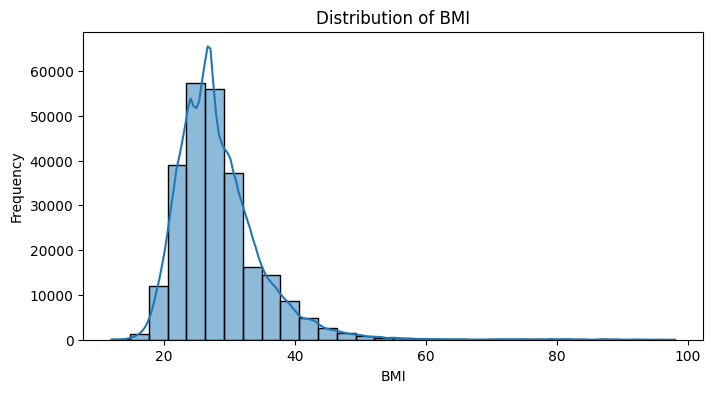

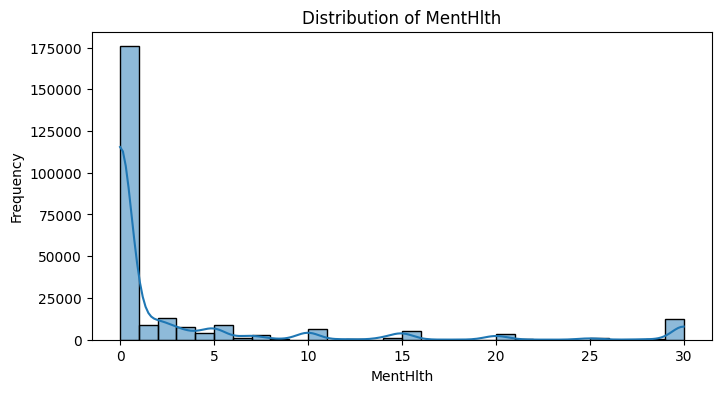

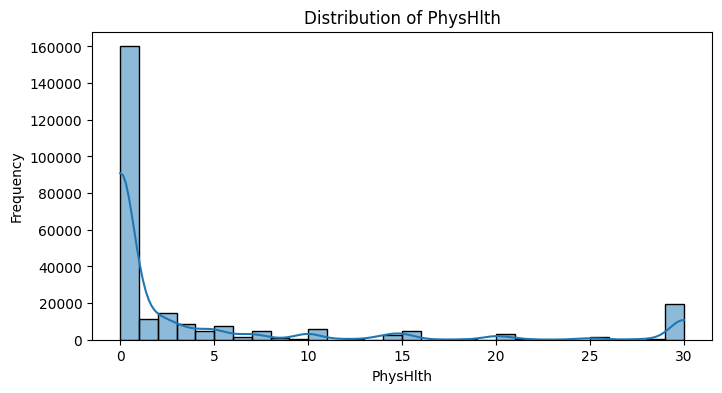

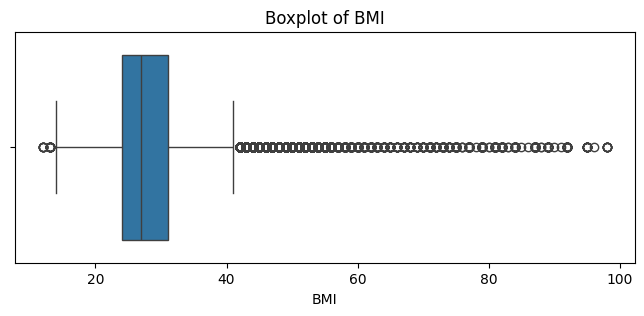

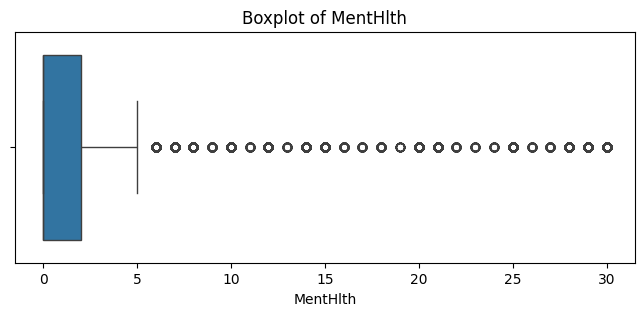

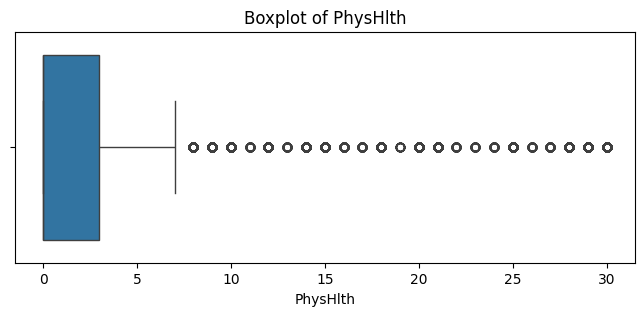


===== HighBP =====
HighBP
0.0    144851
1.0    108829
Name: count, dtype: int64

===== HighChol =====
HighChol
0.0    146089
1.0    107591
Name: count, dtype: int64

===== CholCheck =====
CholCheck
0.0      9470
1.0    244210
Name: count, dtype: int64

===== Smoker =====
Smoker
0.0    141257
1.0    112423
Name: count, dtype: int64

===== Stroke =====
Stroke
0.0    243388
1.0     10292
Name: count, dtype: int64

===== HeartDiseaseorAttack =====
HeartDiseaseorAttack
0.0    229787
1.0     23893
Name: count, dtype: int64

===== PhysActivity =====
PhysActivity
0.0     61760
1.0    191920
Name: count, dtype: int64

===== Fruits =====
Fruits
0.0     92782
1.0    160898
Name: count, dtype: int64

===== Veggies =====
Veggies
0.0     47839
1.0    205841
Name: count, dtype: int64

===== HvyAlcoholConsump =====
HvyAlcoholConsump
0.0    239424
1.0     14256
Name: count, dtype: int64

===== AnyHealthcare =====
AnyHealthcare
0.0     12417
1.0    241263
Name: count, dtype: int64

===== NoDocbcCost ==

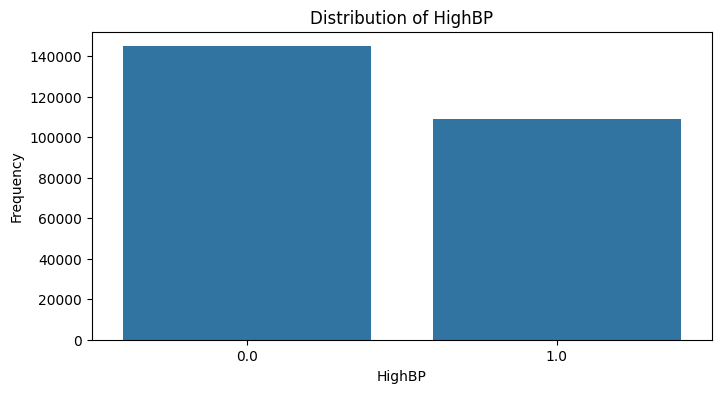

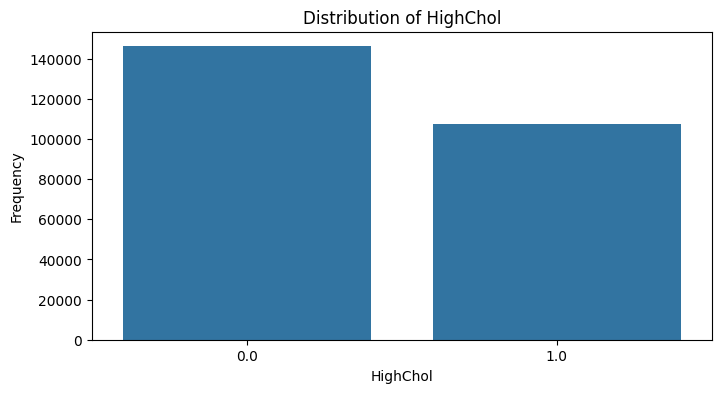

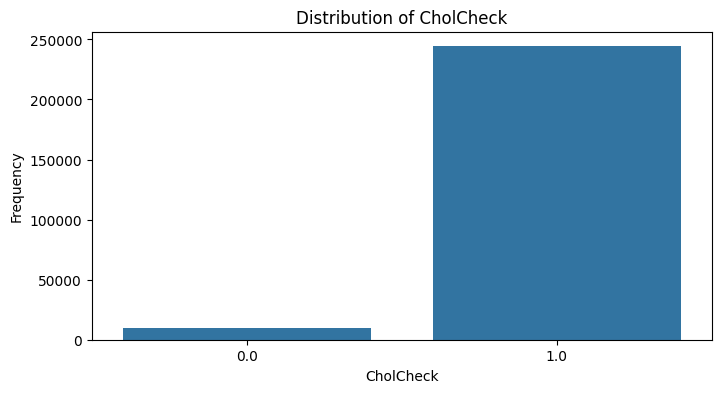

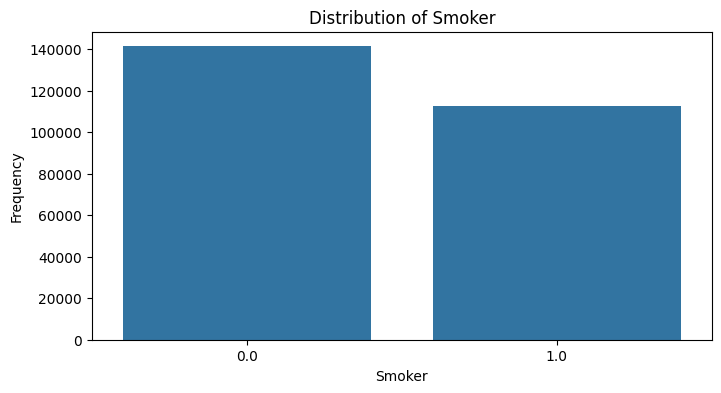

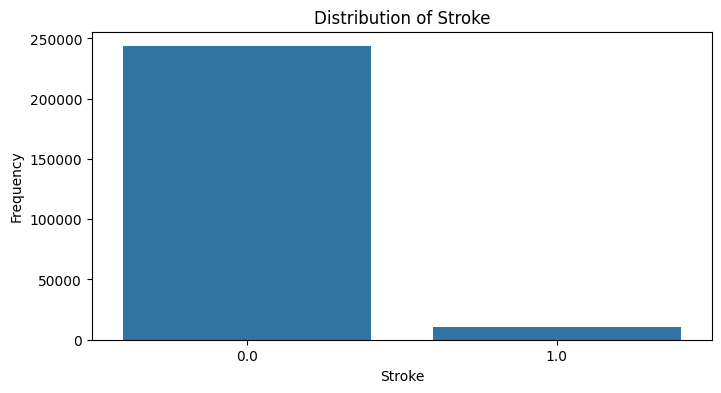

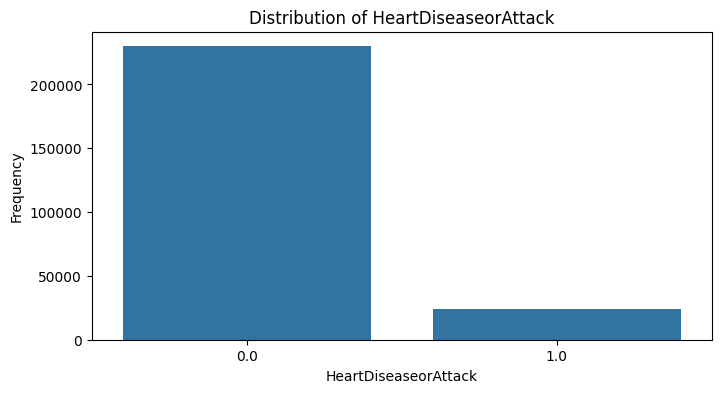

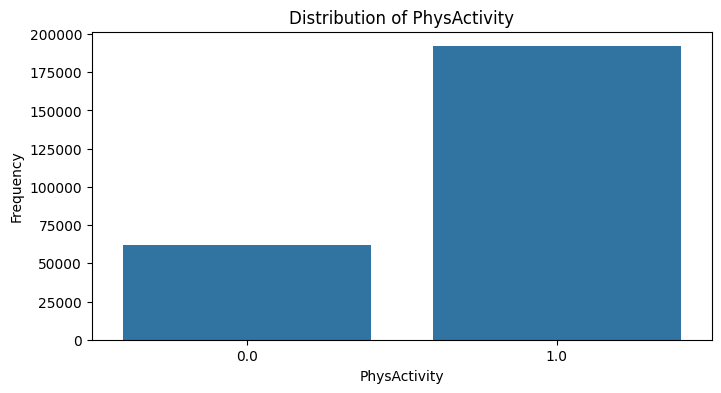

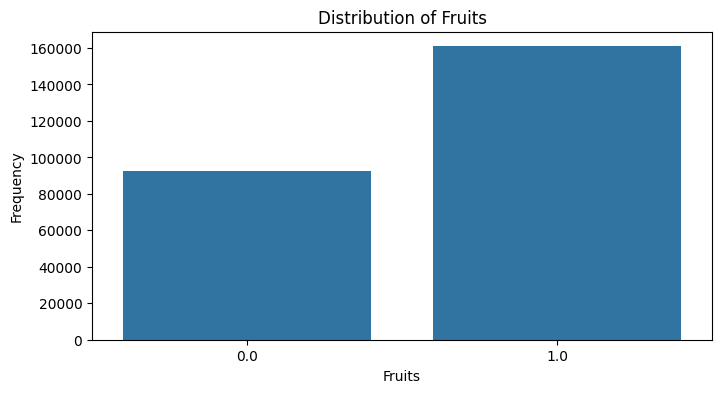

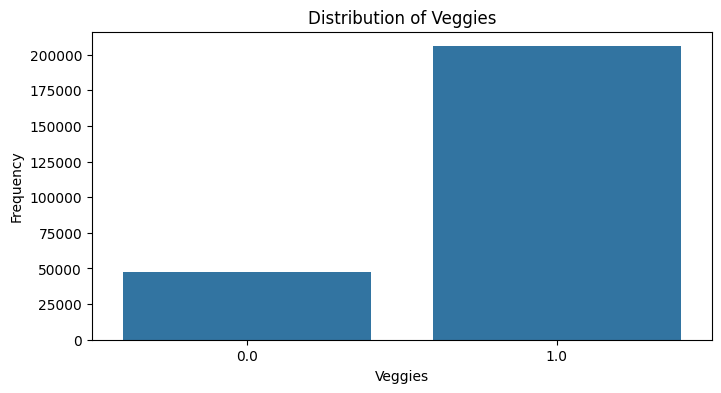

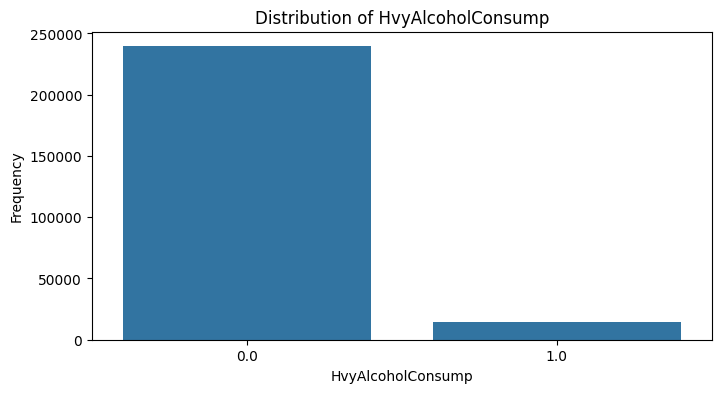

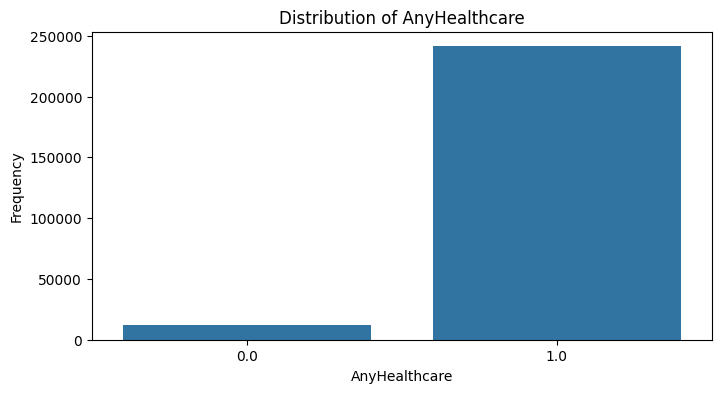

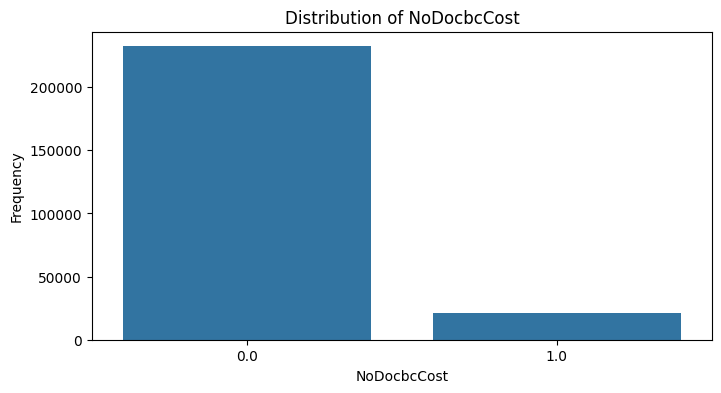

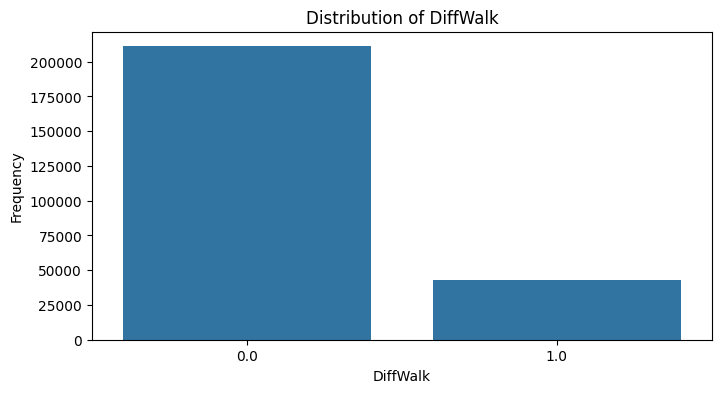

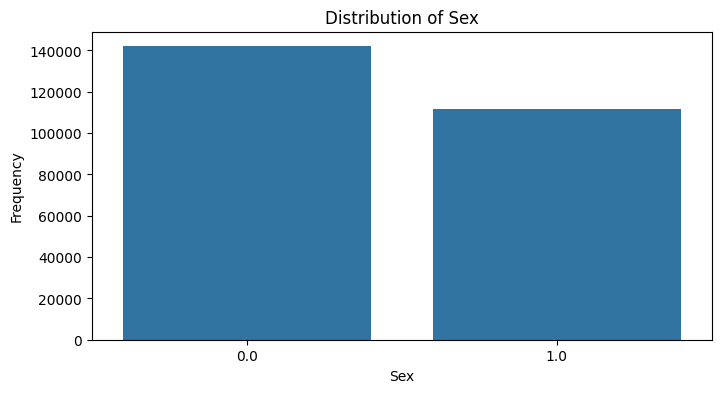

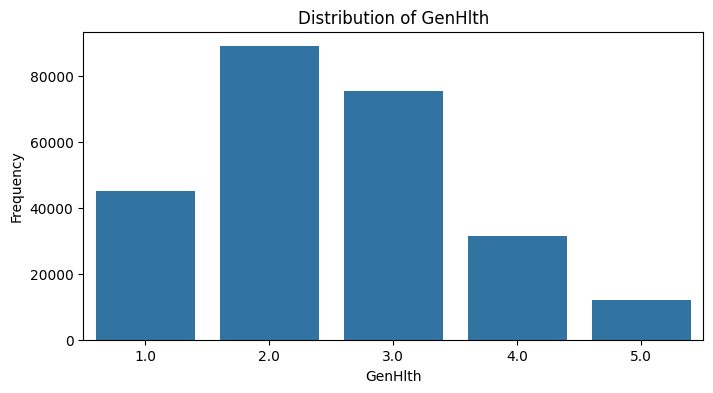

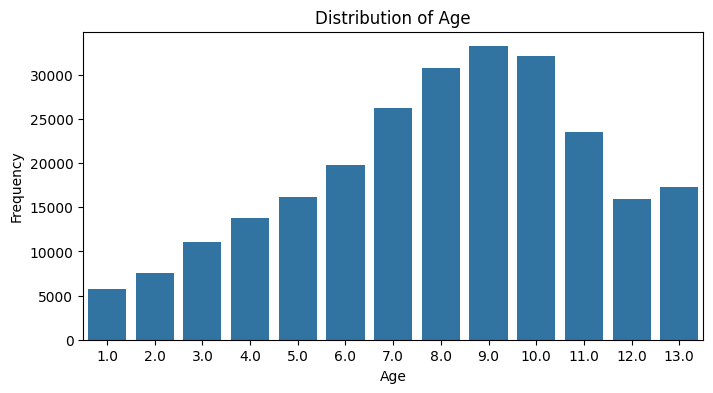

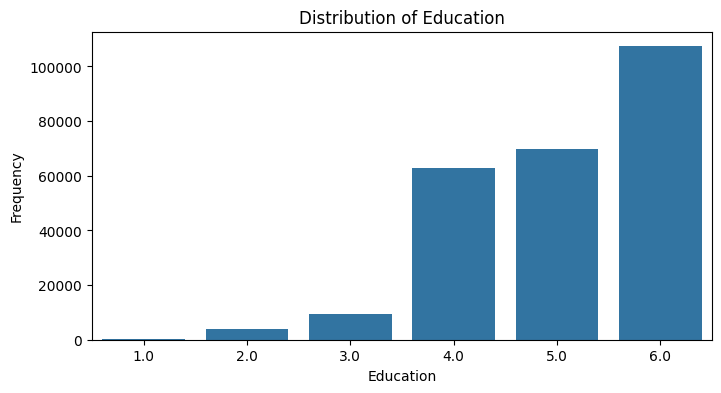

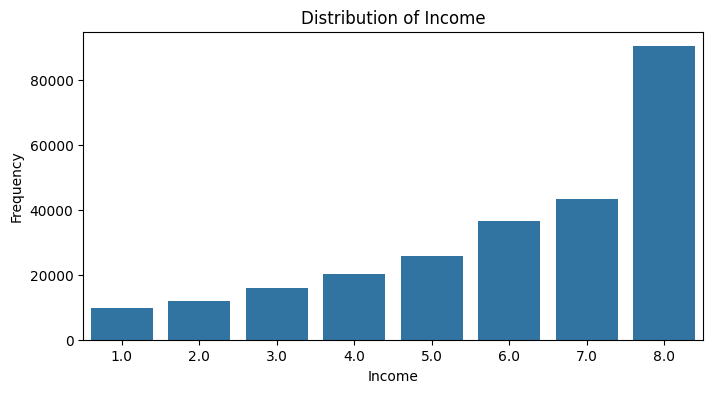


===== BMI theo Diabetes_012 =====


,count,mean,median,std,min,max
Diabetes_012,,,,,,
0.0,213703,27.742521,27.0,6.260993,12.0,98.0
1.0,4631,30.724466,30.0,6.964898,13.0,96.0
2.0,35346,31.944011,31.0,7.363401,13.0,98.0



===== MentHlth theo Diabetes_012 =====


,count,mean,median,std,min,max
Diabetes_012,,,,,,
0.0,213703,2.944404,0.0,7.064440,0.0,30.0
1.0,4631,4.529907,0.0,8.897176,0.0,30.0
2.0,35346,4.461806,0.0,8.947717,0.0,30.0



===== PhysHlth theo Diabetes_012 =====


,count,mean,median,std,min,max
Diabetes_012,,,,,,
0.0,213703,3.582416,0.0,7.999205,0.0,30.0
1.0,4631,6.348305,0.0,10.298013,0.0,30.0
2.0,35346,7.954479,1.0,11.301491,0.0,30.0


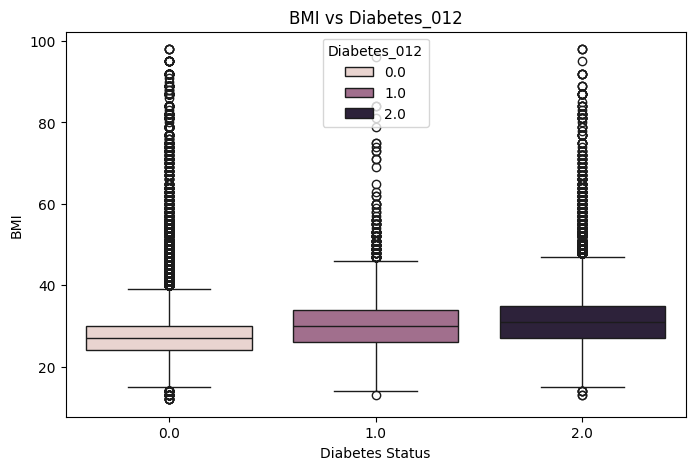

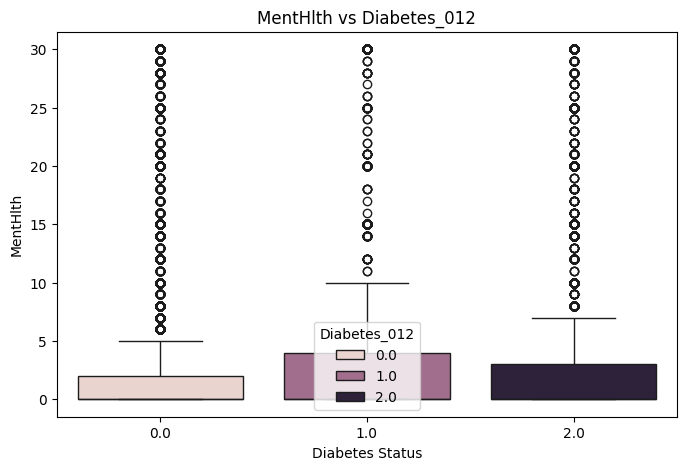

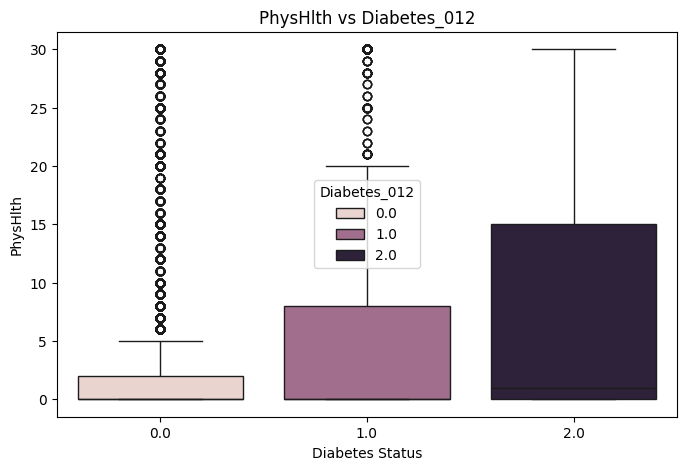


===== HighBP vs Diabetes_012 =====


Diabetes_012,0.0,1.0,2.0
HighBP,,,
0.0,134391,1718,8742
1.0,79312,2913,26604



===== HighChol vs Diabetes_012 =====


Diabetes_012,0.0,1.0,2.0
HighChol,,,
0.0,132673,1756,11660
1.0,81030,2875,23686



===== CholCheck vs Diabetes_012 =====


Diabetes_012,0.0,1.0,2.0
CholCheck,,,
0.0,9167,62,241
1.0,204536,4569,35105


... (62 outputs left out)


===== Tỷ lệ Education vs Diabetes_012 =====


Diabetes_012,0.0,1.0,2.0
Education,,,
1.0,71.84,1.15,27.01
2.0,66.76,3.98,29.26
3.0,72.46,3.31,24.22
4.0,80.21,2.15,17.64
5.0,83.28,1.91,14.81
6.0,88.94,1.37,9.69



===== Tỷ lệ Income vs Diabetes_012 =====


Diabetes_012,0.0,1.0,2.0
Income,,,
1.0,72.51,3.20,24.29
2.0,70.79,3.02,26.19
3.0,75.06,2.63,22.31
4.0,77.59,2.28,20.13
5.0,80.33,2.27,17.40
6.0,83.44,2.05,14.51
7.0,86.12,1.70,12.18
8.0,90.92,1.12,7.96


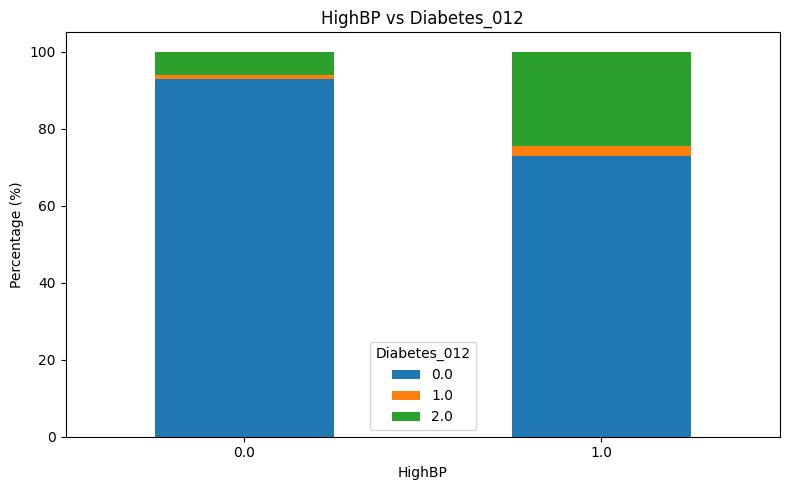

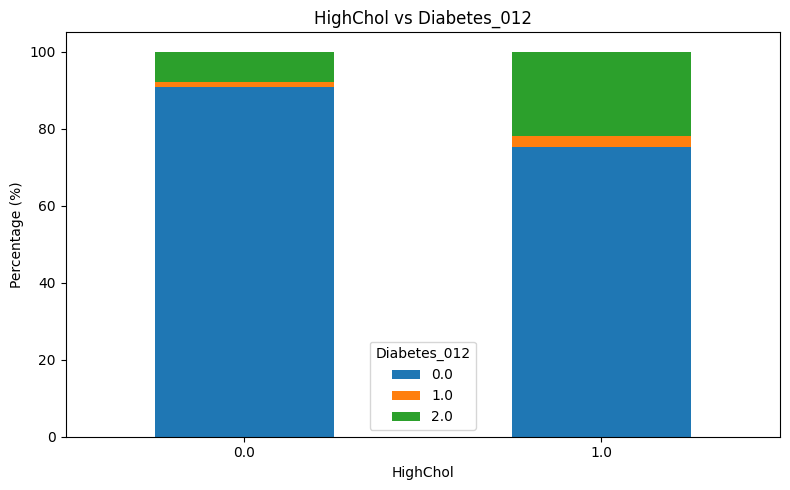

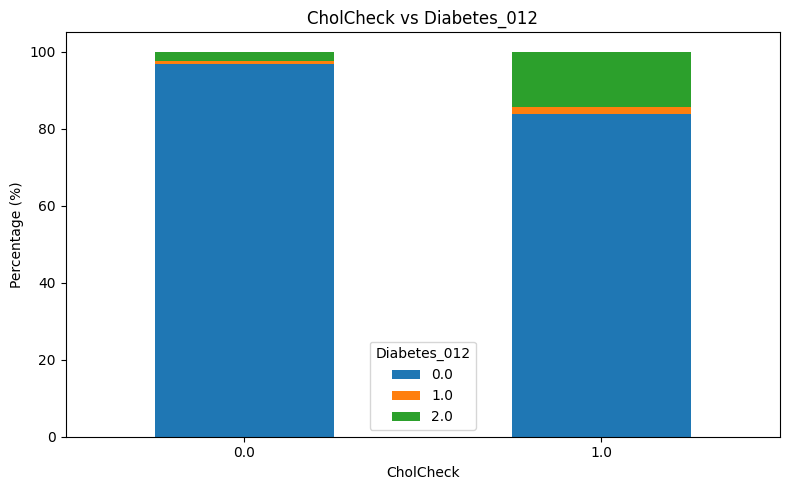

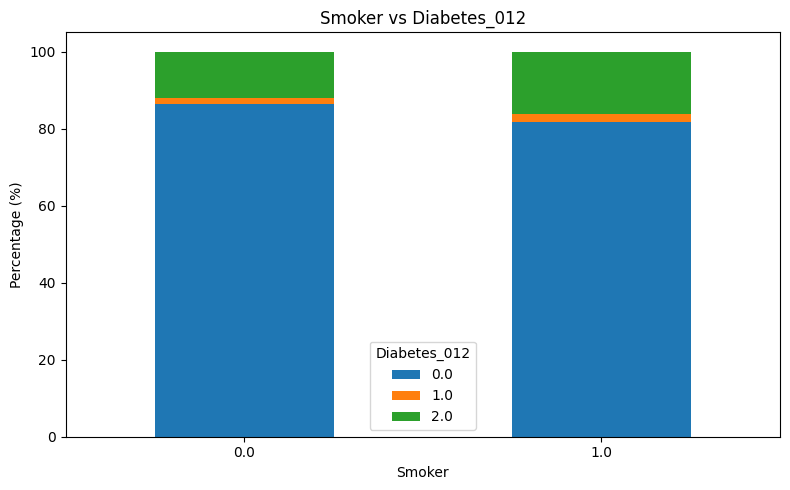

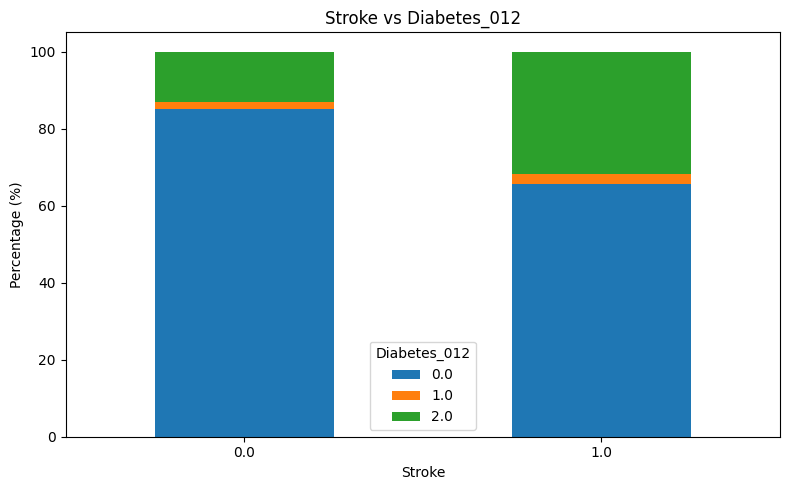

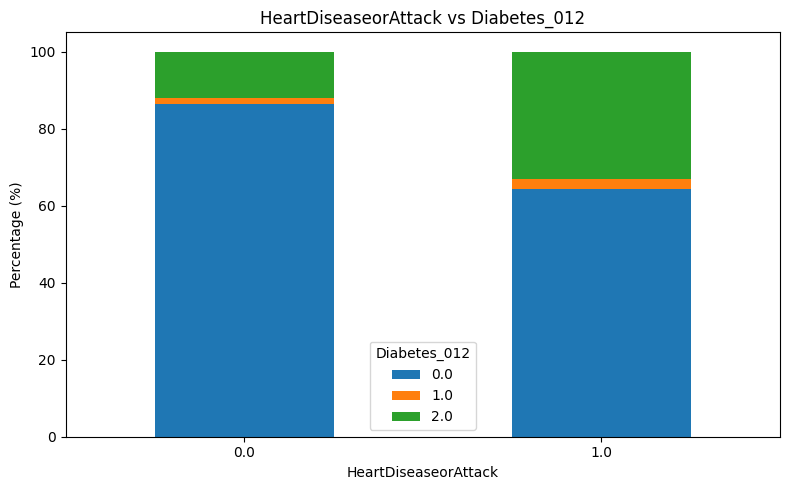

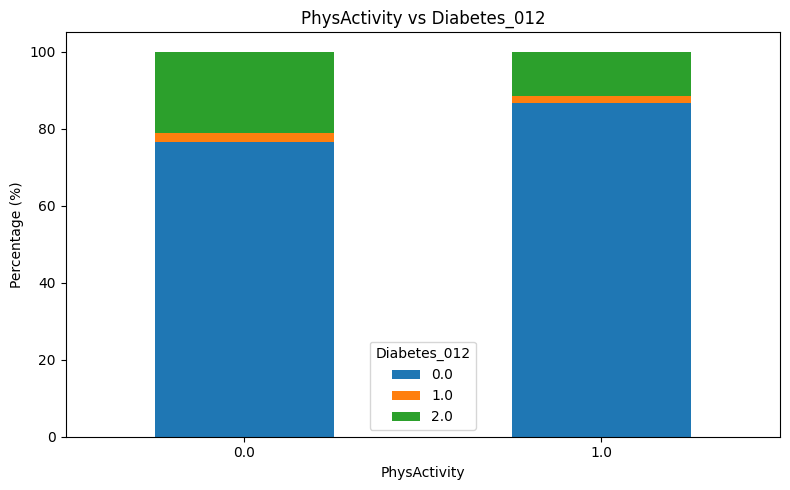

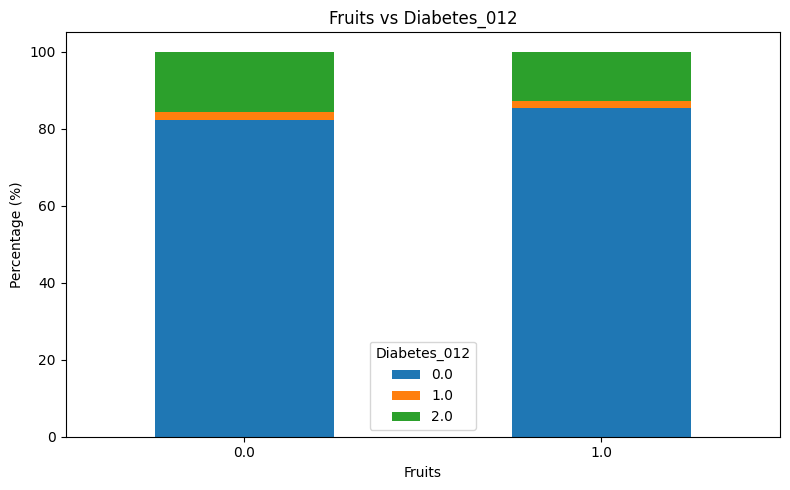

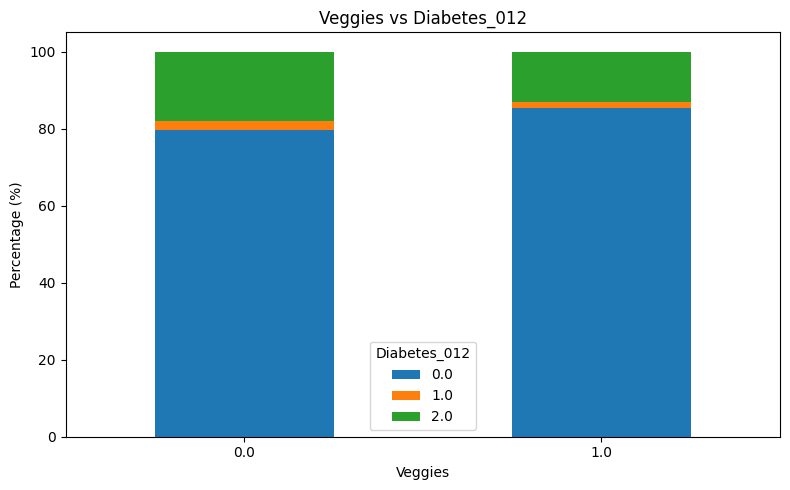

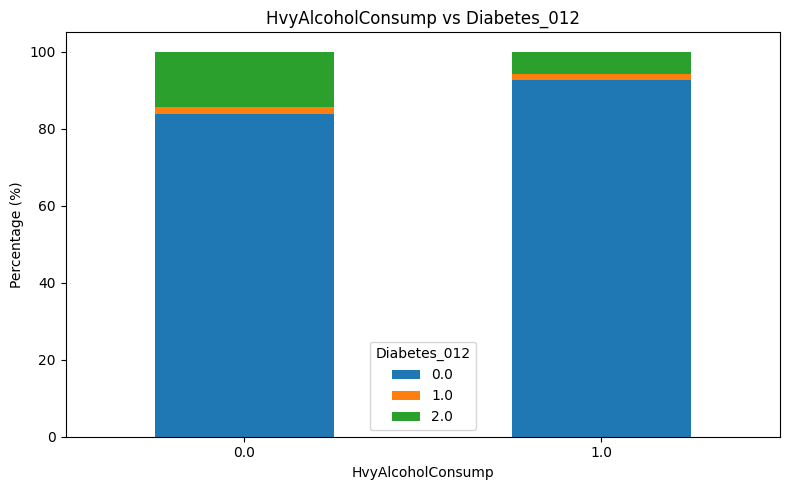

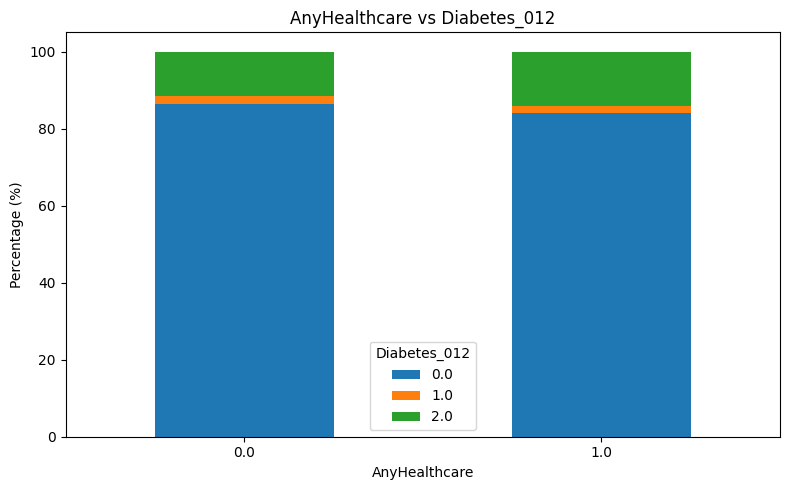

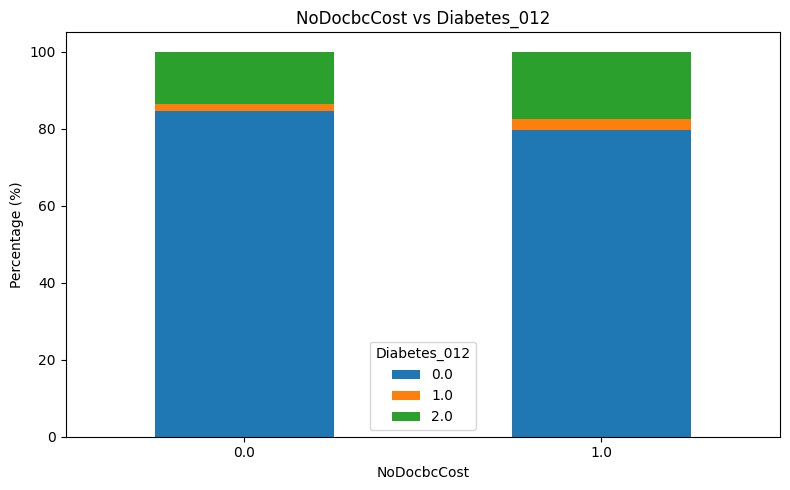

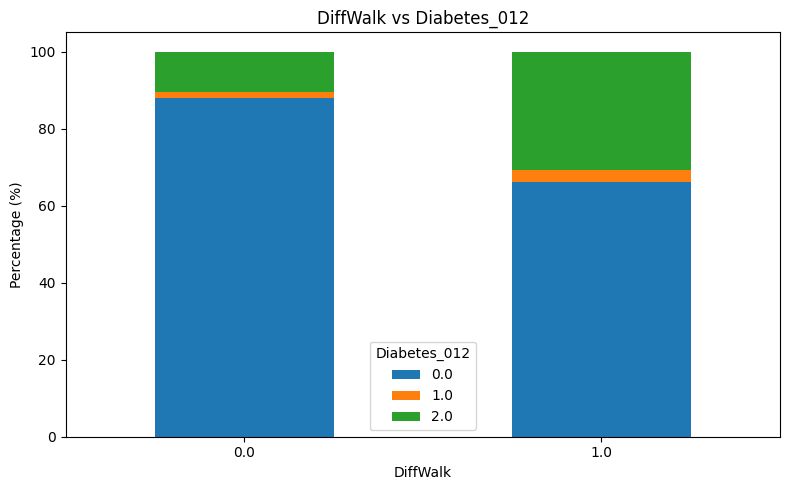

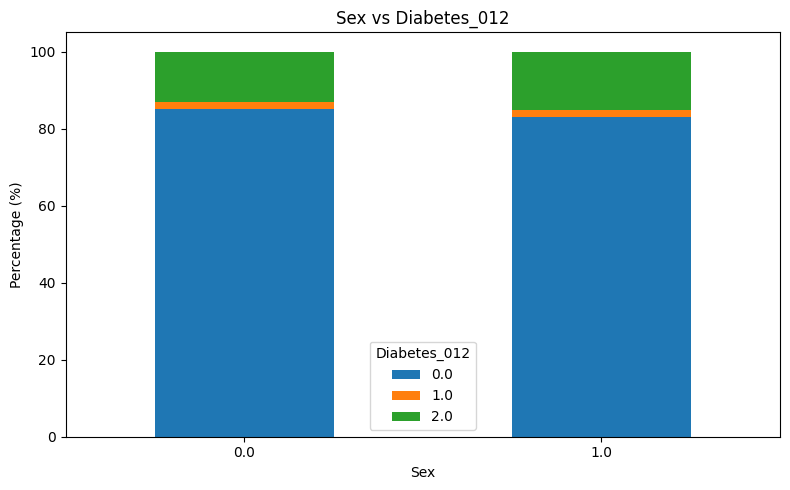

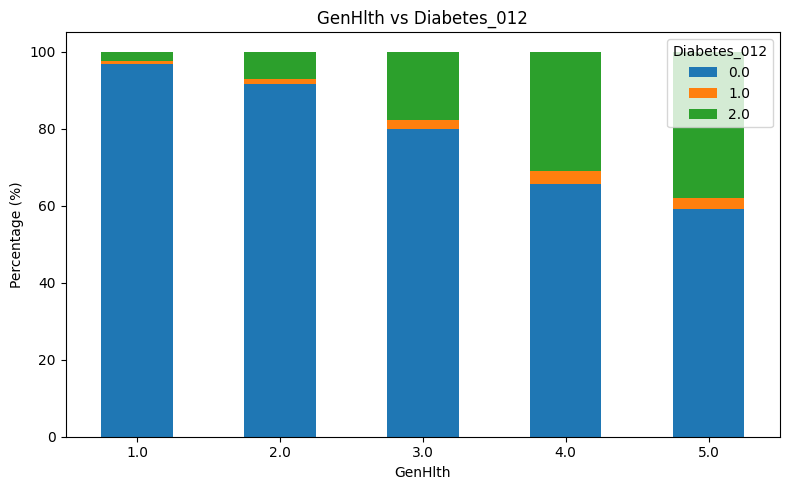

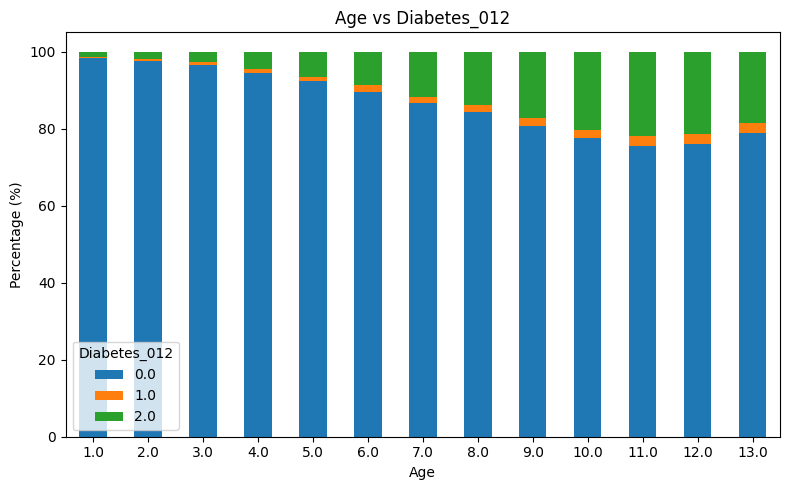

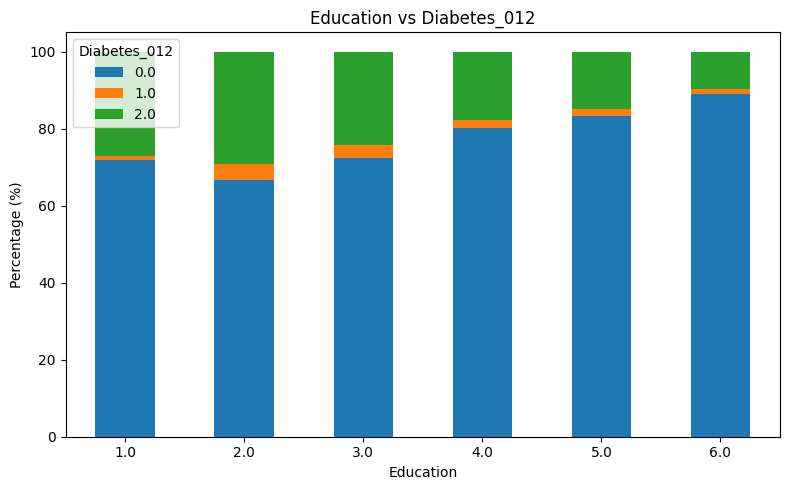

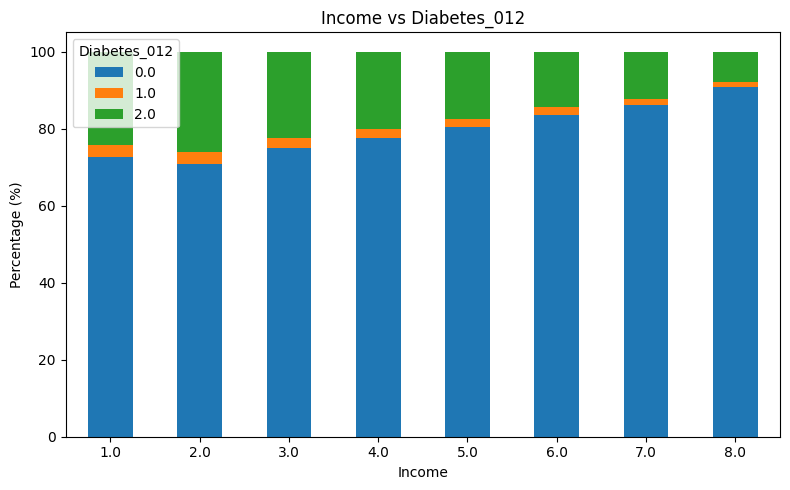

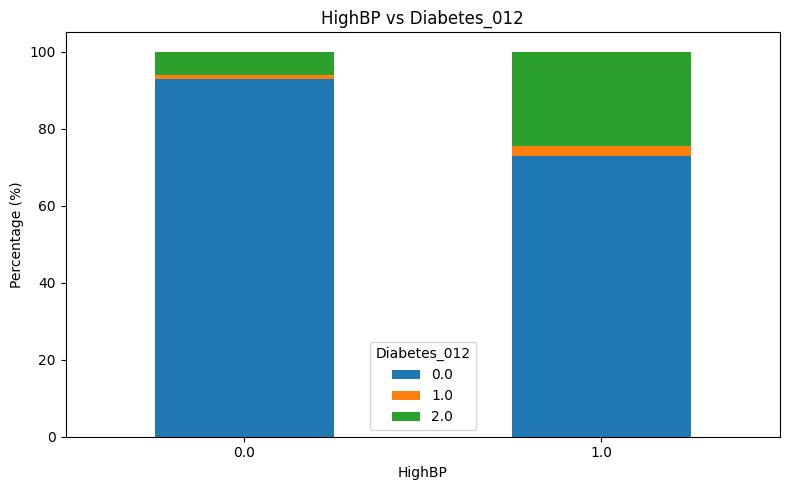

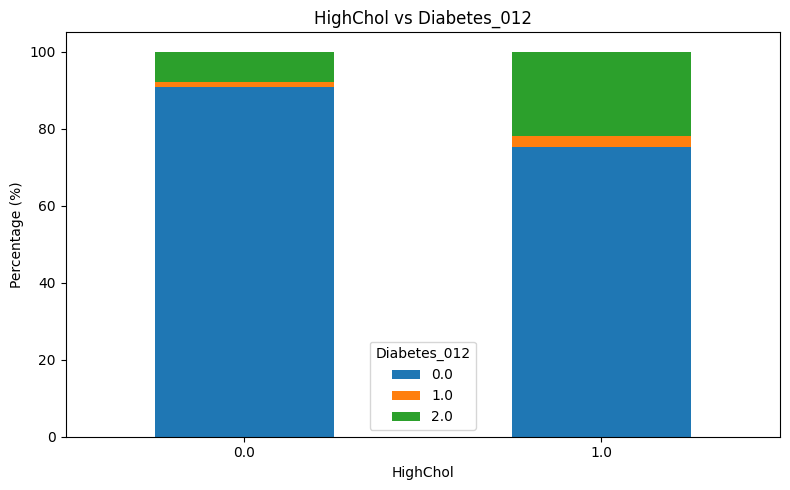

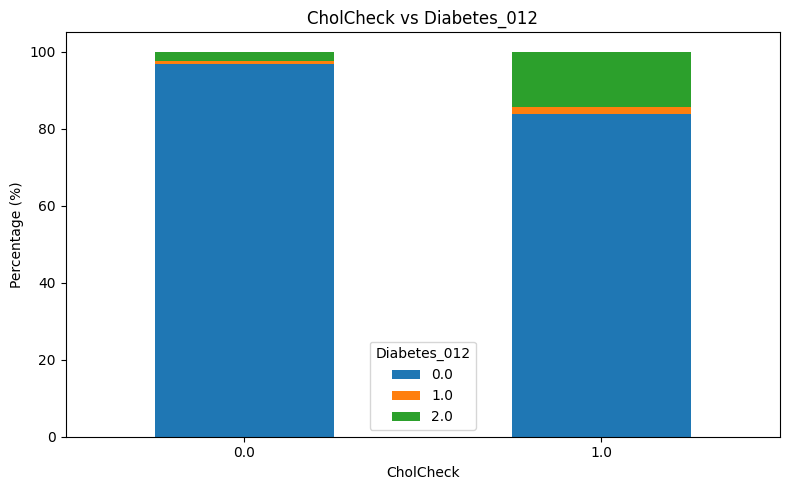

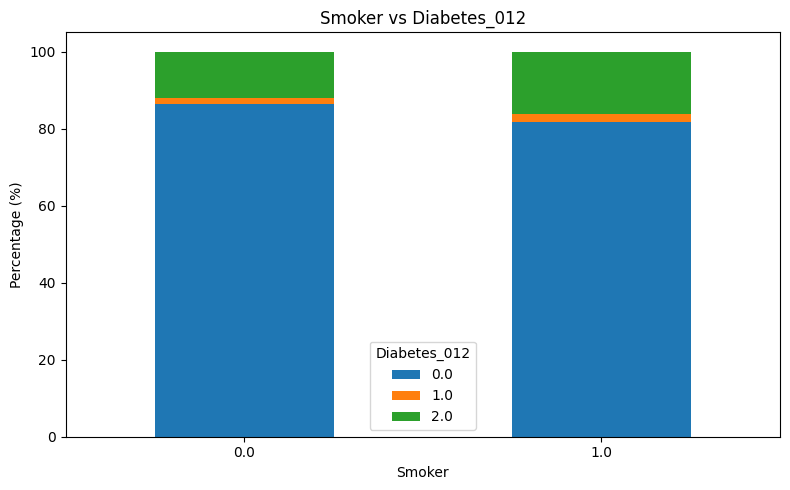

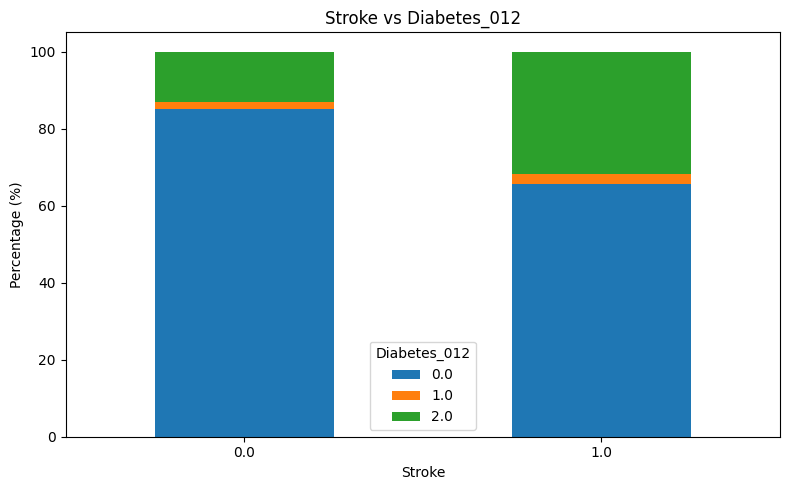

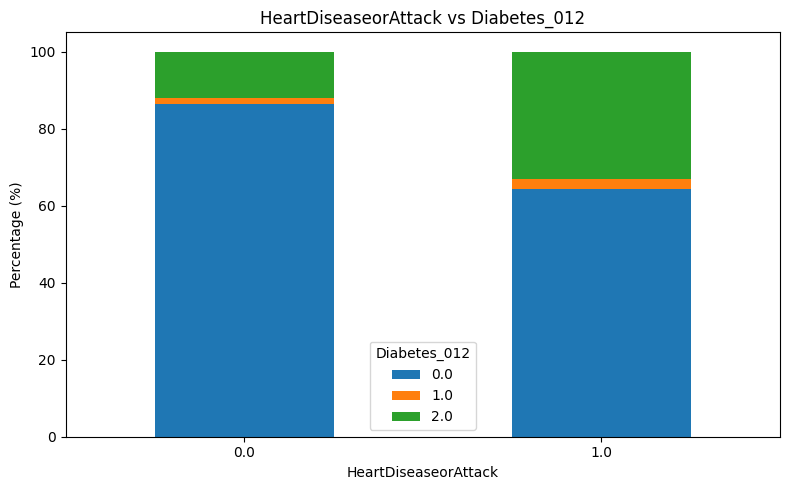

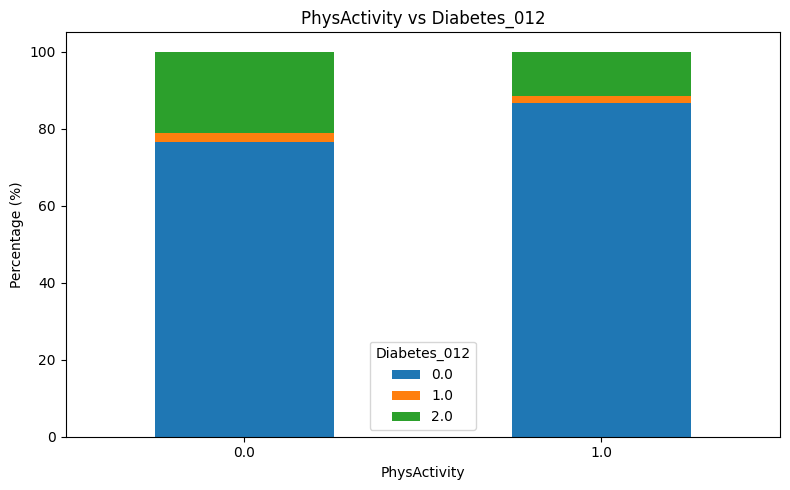

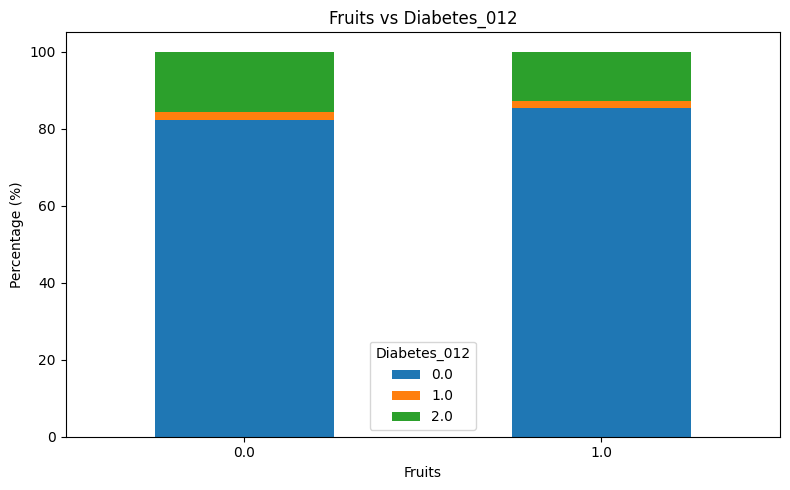

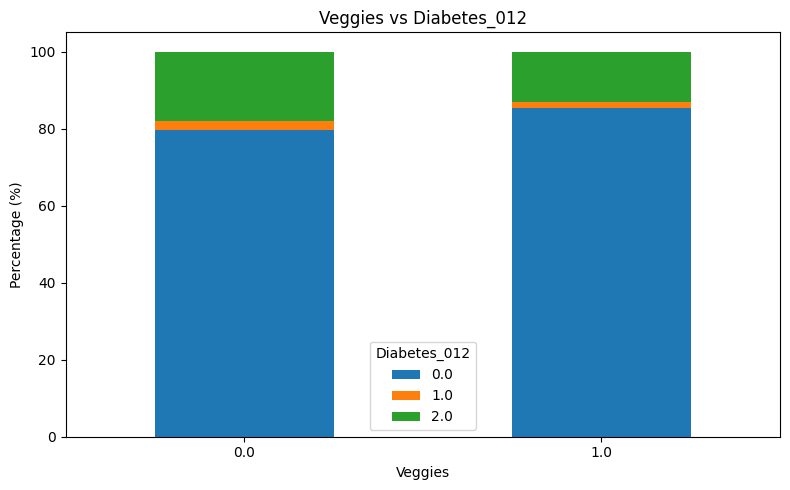

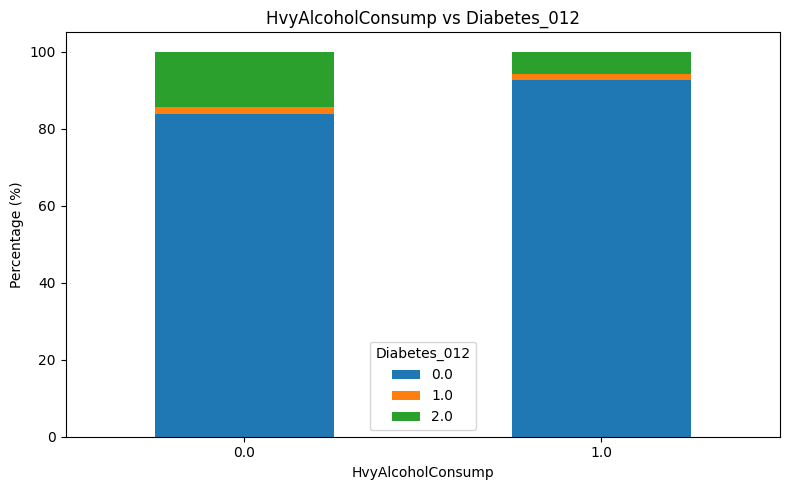

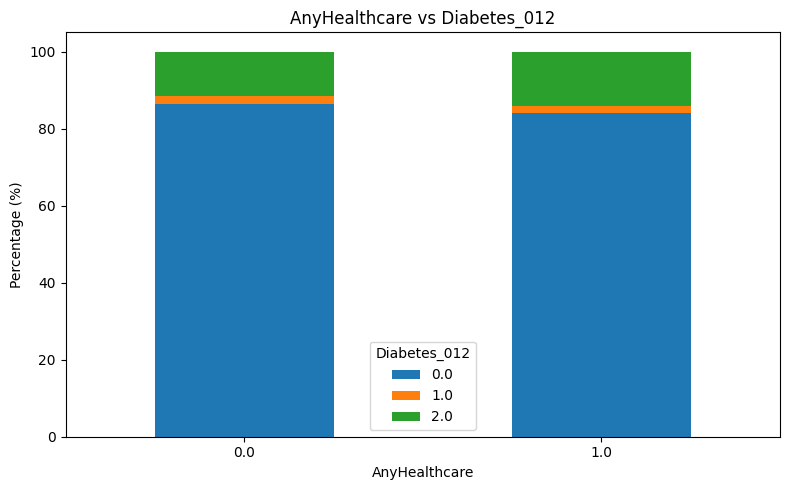

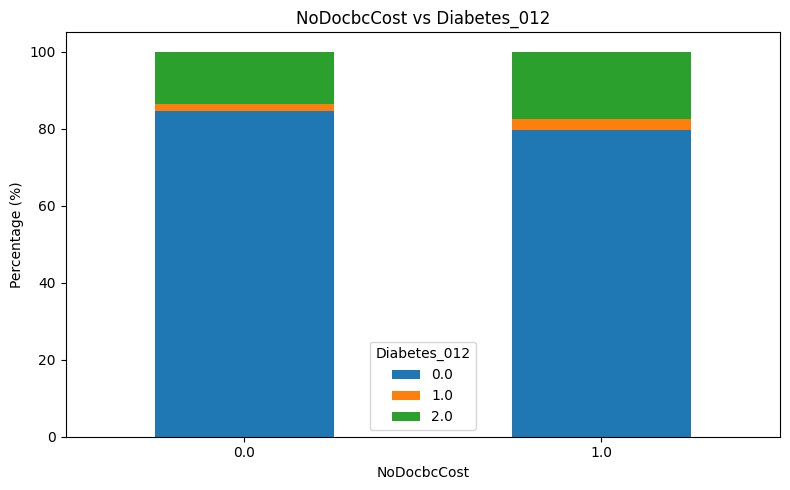

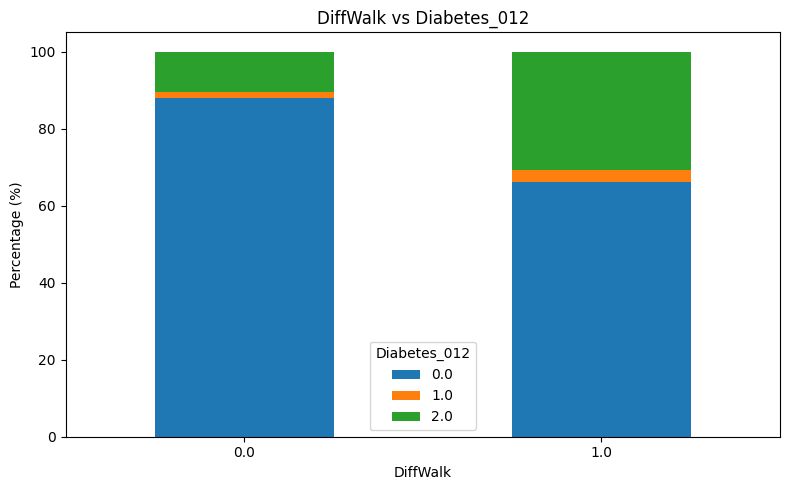

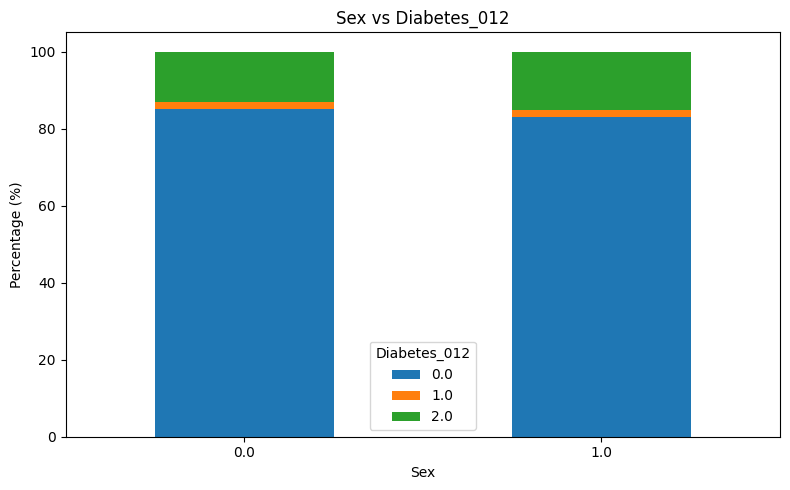

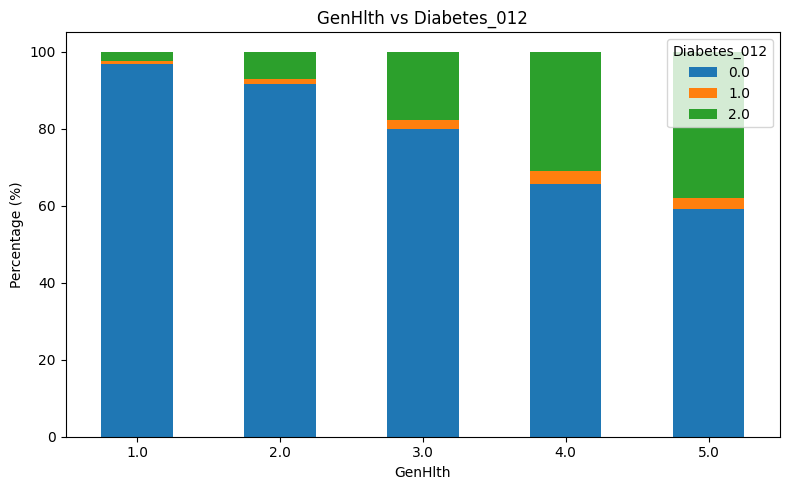

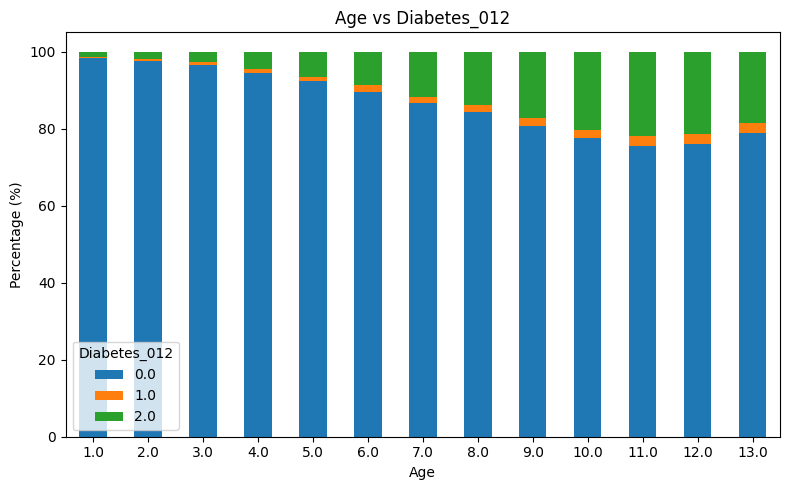

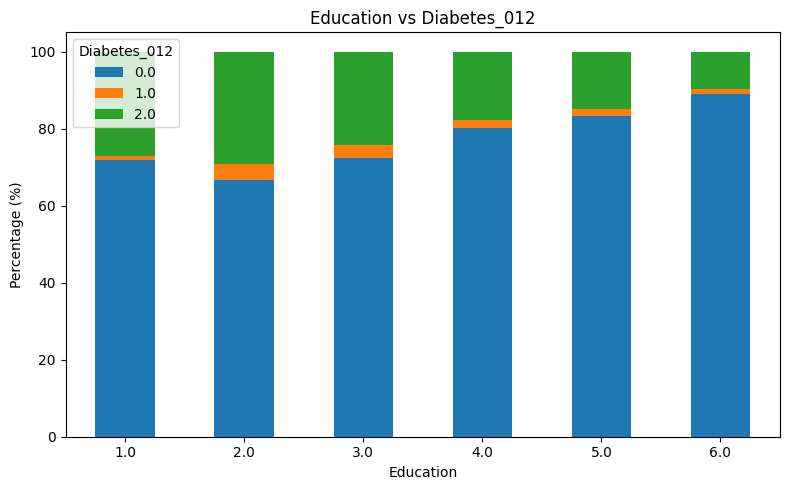

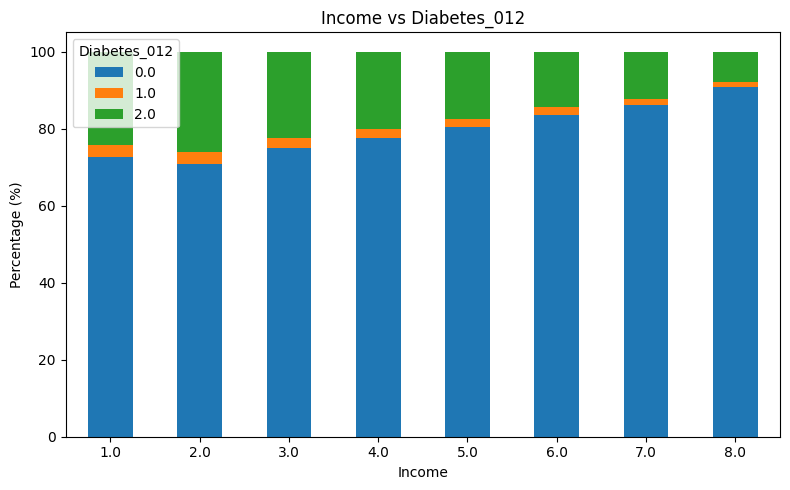

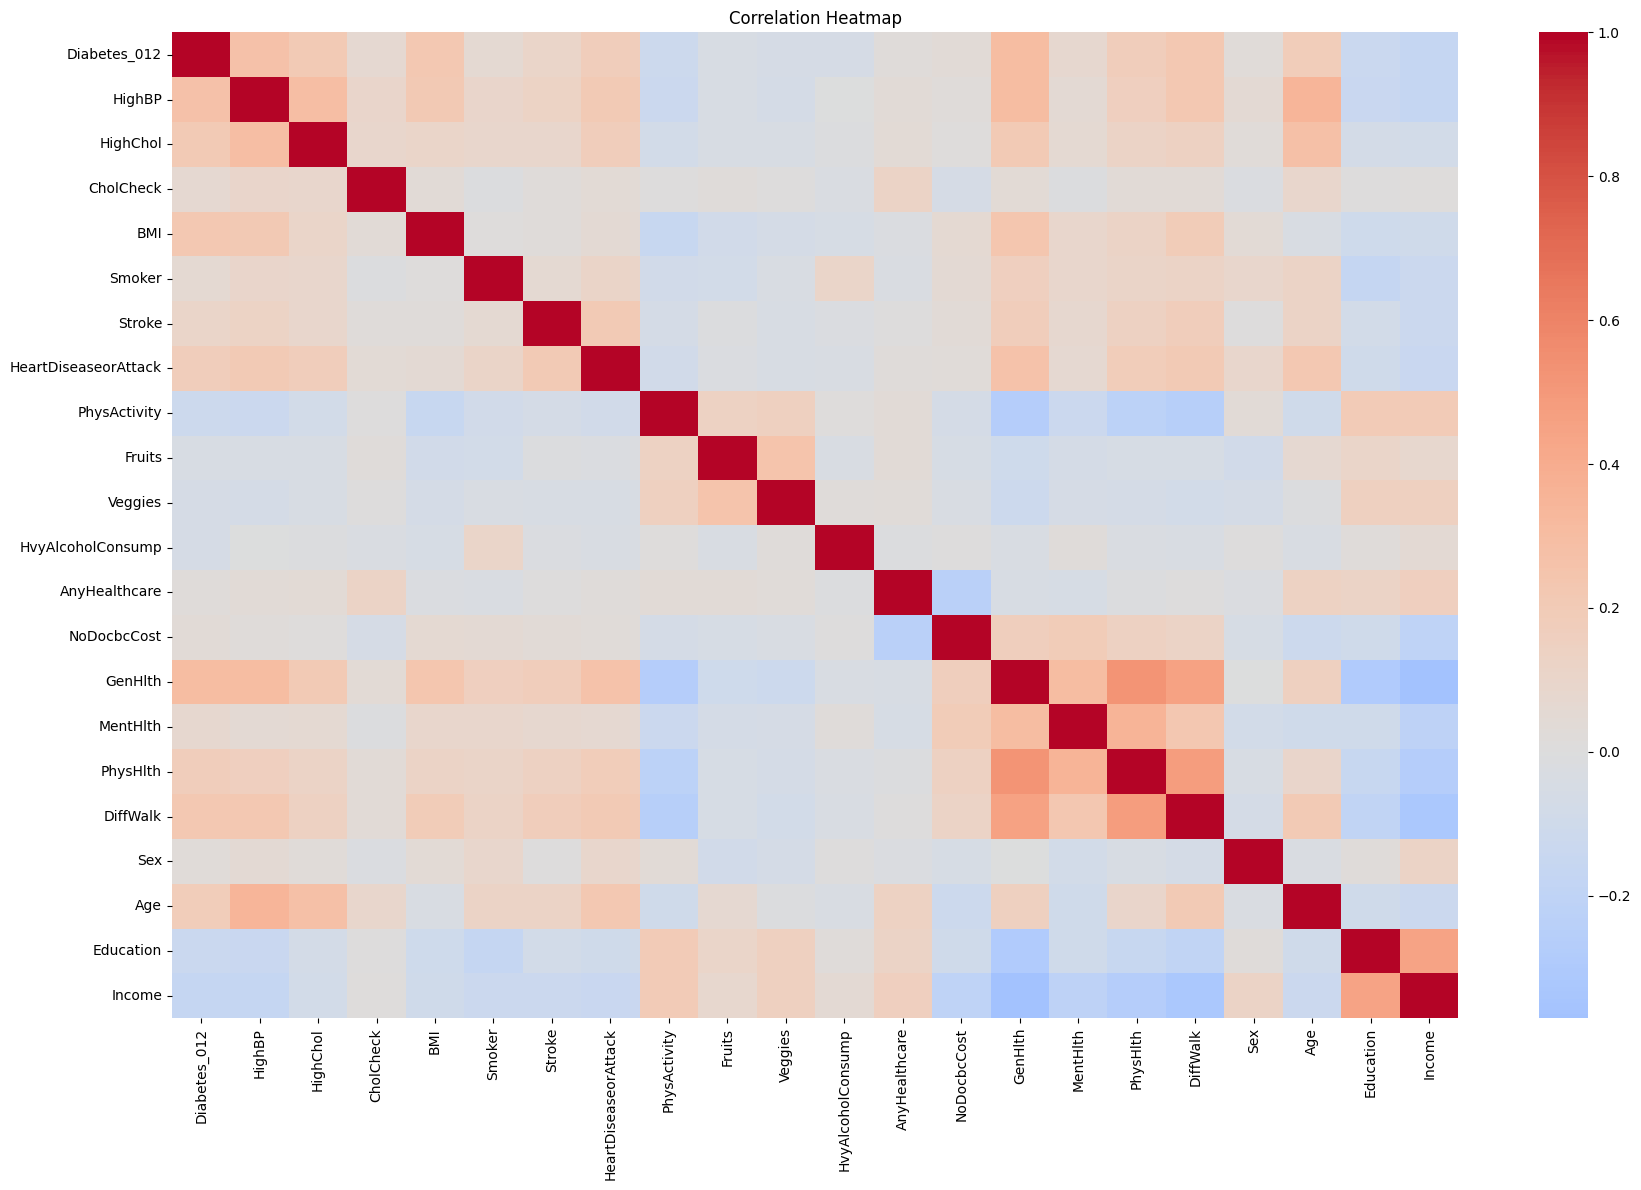

,Feature,MI Score
13,GenHlth,0.047067
0,HighBP,0.037435
3,BMI,0.030067
18,Age,0.022087
1,HighChol,0.022049
16,DiffWalk,0.021242
20,Income,0.015080
15,PhysHlth,0.014923
6,HeartDiseaseorAttack,0.013050
19,Education,0.008582


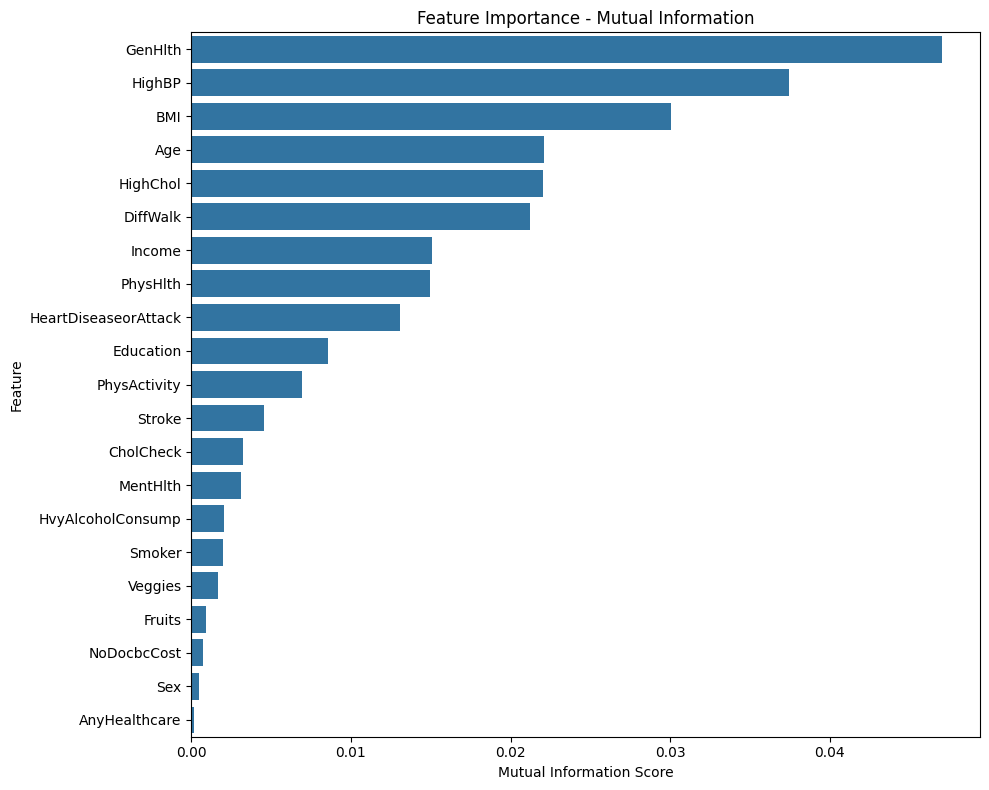

In [24]:
#Xác định biến mục tiêu
target = 'Diabetes_012'

print(train_df[target].value_counts())
# Thống kê mô tả
train_df[numerical_features].describe().T
import matplotlib.pyplot as plt
import seaborn as sns
#Numerical Features
for col in numerical_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=train_df, x=col, bins=30, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()
for col in numerical_features:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=train_df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()
#Categorical Features
categorical_features = nominal_features + ordinal_features

for col in categorical_features:
    print(f"\n===== {col} =====")
    print(train_df[col].value_counts().sort_index())
for col in categorical_features:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=train_df, x=col)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()
for col in numerical_features:
    print(f"\n===== {col} theo Diabetes_012 =====")

    display(
        train_df.groupby(target)[col].agg(
            ['count', 'mean', 'median', 'std', 'min', 'max']
        )
    )
for col in numerical_features:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=train_df,
        x=target,
        y=col,
        hue=target
    )

    plt.title(f'{col} vs Diabetes_012')
    plt.xlabel('Diabetes Status')
    plt.ylabel(col)
    plt.show()
for col in categorical_features:
    print(f"\n===== {col} vs {target} =====")

    display(pd.crosstab(
        train_df[col],
        train_df[target]
    ))
for col in categorical_features:
    print(f"\n===== Tỷ lệ {col} vs {target} =====")

    display(
        pd.crosstab(
            train_df[col],
            train_df[target],
            normalize='index'
        ).mul(100).round(2)
    )
for col in categorical_features:
    cross_data = pd.crosstab(
        train_df[col],
        train_df[target],
        normalize='index'
    ) * 100

    cross_data.plot(
        kind='bar',
        stacked=True,
        figsize=(8, 5)
    )

    plt.title(f'{col} vs Diabetes_012')
    plt.xlabel(col)
    plt.ylabel('Percentage (%)')
    plt.legend(title='Diabetes_012')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
for col in categorical_features:
    cross_data = pd.crosstab(
        train_df[col],
        train_df[target],
        normalize='index'
    ) * 100

    cross_data.plot(
        kind='bar',
        stacked=True,
        figsize=(8, 5)
    )

    plt.title(f'{col} vs Diabetes_012')
    plt.xlabel(col)
    plt.ylabel('Percentage (%)')
    plt.legend(title='Diabetes_012')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
plt.figure(figsize=(18, 12))

corr = train_df.corr()

sns.heatmap(
    corr,
    cmap='coolwarm',
    annot=False,
    center=0
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()
from sklearn.feature_selection import mutual_info_classif

X = train_df.drop(columns=[target])
y = train_df[target]

mi_scores = mutual_info_classif(
    X,
    y,
    random_state=42,
    discrete_features=True
)

mi_df = pd.DataFrame({
    'Feature': X.columns,
    'MI Score': mi_scores
}).sort_values(
    by='MI Score',
    ascending=False
)

display(mi_df)
plt.figure(figsize=(10, 8))

sns.barplot(
    data=mi_df,
    x='MI Score',
    y='Feature'
)

plt.title('Feature Importance - Mutual Information')
plt.xlabel('Mutual Information Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()